In [ ]:
# --- Step 1: load the cube ---------------------------------------------------
# Loads an .im3 as a (C, Y, X) uint16 array via Bio-Formats. Cached per path, so
# re-running this cell is free.
import os
from pathlib import Path

import numpy as np
import pandas as pd

CUBE = "/Users/zmkoyan/User Files/multi-excitation-hsi-in-vivo-rats/Data/Raw/Rat_Cubes/12.09/Rat_1/Left_leg/Distinct_Cubes/310_20000exp.im3"


def resolve(cube):
    """Absolute paths are used as-is; relative ones are taken from the repo root."""
    p = Path(cube)
    if p.is_absolute():
        return p
    for folder in (Path.cwd(), *Path.cwd().parents):
        if (folder / "Data").is_dir():
            return folder / cube
    raise FileNotFoundError(f"could not find a Data/ folder above {Path.cwd()}")


def load_cube(cube):
    """Load an .im3 as (C, Y, X) uint16."""
    path = resolve(cube)
    cache = globals().setdefault("_CUBE_CACHE", {})
    if str(path) in cache:
        return cache[str(path)]
    if not path.exists():
        near = sorted(path.parent.glob("*.im3"))[:6] or sorted(
            resolve("Data/Raw").rglob("*.im3"))[:6]
        raise FileNotFoundError(f"{path} not found.\nNearby:\n  "
                                + "\n  ".join(str(q) for q in near))
    # Must happen BEFORE the first bioio import: once the JVM starts the Maven
    # repository list is frozen. maven.scijava.org is unreachable on this
    # network, so point scyjava at the OME Artifactory instead.
    os.environ.setdefault("JAVA_HOME", "/opt/homebrew/opt/openjdk")
    import scyjava.config as cfg

    cfg._repositories.pop("scijava.public", None)
    cfg.add_repositories({"ome": "https://artifacts.openmicroscopy.org/artifactory/maven"})
    from bioio import BioImage
    import bioio_bioformats

    arr = BioImage(str(path), reader=bioio_bioformats.Reader).get_image_data("CYX")
    cache[str(path)] = arr
    return arr


path = resolve(CUBE)
data = load_cube(CUBE)
C, H, W = data.shape
print(f"loaded {path.name}  ({path.stat().st_size / 1e6:.1f} MB on disk)")


In [ ]:
# --- Step 2: shapes ----------------------------------------------------------
print(f"file        : {path}")
print(f"shape       : {data.shape}  (C={C} channels, Y={H} rows, X={W} cols)")
print(f"dtype       : {data.dtype}")
print(f"pixels/chan : {H * W:,}")
print(f"values total: {data.size:,}")
print(f"in memory   : {data.nbytes / 1e6:.1f} MB")


In [ ]:
# --- Step 3: value statistics per channel ------------------------------------
# One row per channel. SAT% is the share of pixels at or above the sensor's
# clipping level (the camera tops out at 4040 counts), so a high SAT% means that
# channel's bright values are censored and its max/percentiles are not real.
SAT = 4040

flat = data.reshape(C, -1)                      # (C, Y*X) view, no copy
q = np.percentile(flat, [1, 50, 99], axis=1)    # rows: p1, median, p99

stats = pd.DataFrame({
    "chan":   np.arange(C),
    "min":    flat.min(axis=1),
    "p1":     q[0],
    "median": q[1],
    "mean":   flat.mean(axis=1, dtype=np.float64),
    "p99":    q[2],
    "max":    flat.max(axis=1),
    "std":    flat.std(axis=1, dtype=np.float64),
    "zero%":  100.0 * (flat == 0).mean(axis=1),
    "sat%":   100.0 * (flat >= SAT).mean(axis=1),
}).set_index("chan")

with pd.option_context("display.max_rows", None, "display.float_format", "{:.2f}".format):
    display(stats)

print(f"\nwhole cube: min={data.min()}  max={data.max()}  "
      f"mean={data.mean(dtype=np.float64):.2f}  std={data.std(dtype=np.float64):.2f}")
print(f"channels with any saturated pixel: "
      f"{int((stats['sat%'] > 0).sum())}/{C}")


In [ ]:
# --- Step 4: value distribution per channel ----------------------------------
# x = channel, y = pixel value, colour = how many pixels of that channel fall in
# that value bin (white = empty bin). Counts are log-scaled: ~2/3 of every
# channel is exactly 0 — the dark surround — so on a linear scale that bottom
# row would swamp everything, and for the same reason the median of every
# channel is 0 and not worth drawing. The mean and 99th-percentile lines trace
# where the lit pixels sit; the dashed line is the 4040-count sensor clip, where
# the bright tail of channels 2-15 piles up instead of continuing upward.
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

NBINS = 128
edges = np.linspace(0, float(data.max()) + 1, NBINS + 1)

hist = np.stack([np.histogram(flat[c], bins=edges)[0] for c in range(C)], axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(np.ma.masked_equal(hist, 0), origin="lower", aspect="auto",
               extent=[-0.5, C - 0.5, edges[0], edges[-1]],
               norm=LogNorm(vmin=1, vmax=hist.max()), cmap="magma",
               interpolation="nearest")

ax.plot(stats.index, stats["p99"], color="white", lw=1.5, label="99th pct")
ax.plot(stats.index, stats["mean"], color="cyan", lw=1.5, ls="--", label="mean")
ax.axhline(SAT, color="red", ls="--", lw=1, label=f"sensor clip ({SAT})")

ax.set_xlabel("channel")
ax.set_ylabel("pixel value (counts)")
ax.set_title(f"{path.name} — distribution of pixel values per channel")
ax.set_xticks(stats.index[::2])
ax.set_ylim(0, edges[-1] * 1.04)
ax.legend(loc="upper right", framealpha=0.9)
fig.colorbar(im, ax=ax, label="pixels per bin (log)")
fig.tight_layout()
plt.show()

# Same data as a stack of ordinary histograms, if you would rather read curves:
# for c in range(C):
#     ax2.step(edges[:-1], hist[:, c], where="post", lw=0.8)


42 cubes under /Users/zmkoyan/User Files/multi-excitation-hsi-in-vivo-rats/Data/Raw/Rat_Cubes/12.09



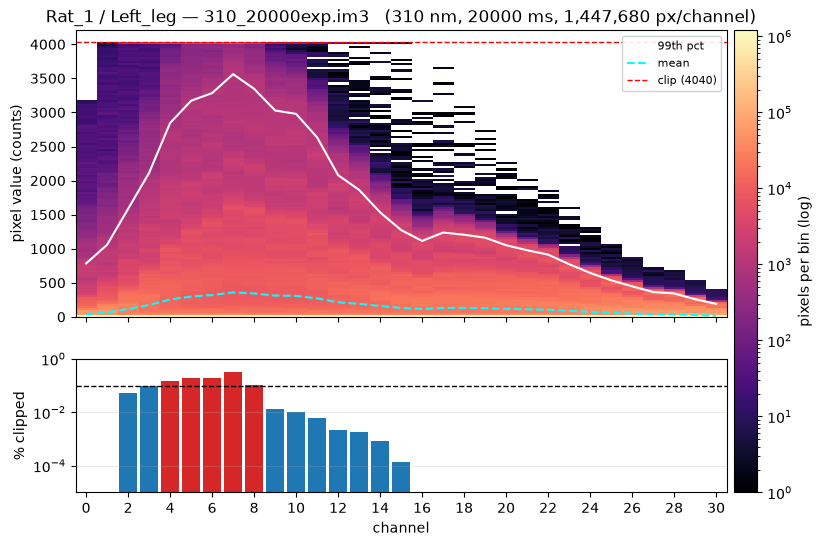

Rat_1/Left_leg/310_20000exp.im3     worst   0.32%   over 0.1%: 4-8


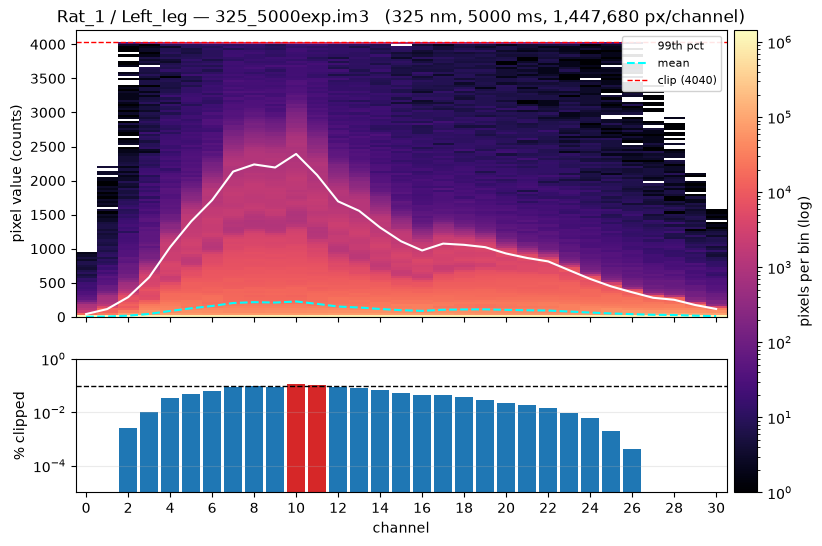

Rat_1/Left_leg/325_5000exp.im3      worst   0.11%   over 0.1%: 10-11


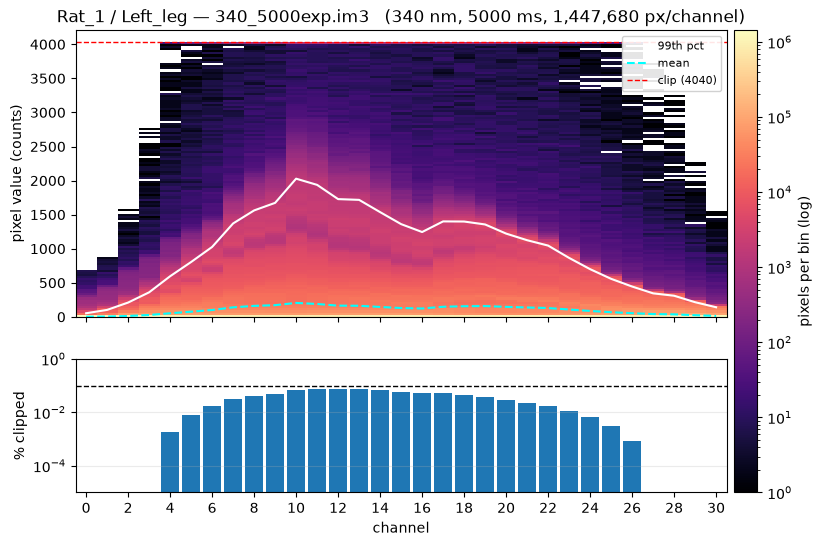

Rat_1/Left_leg/340_5000exp.im3      worst   0.08%   over 0.1%: none


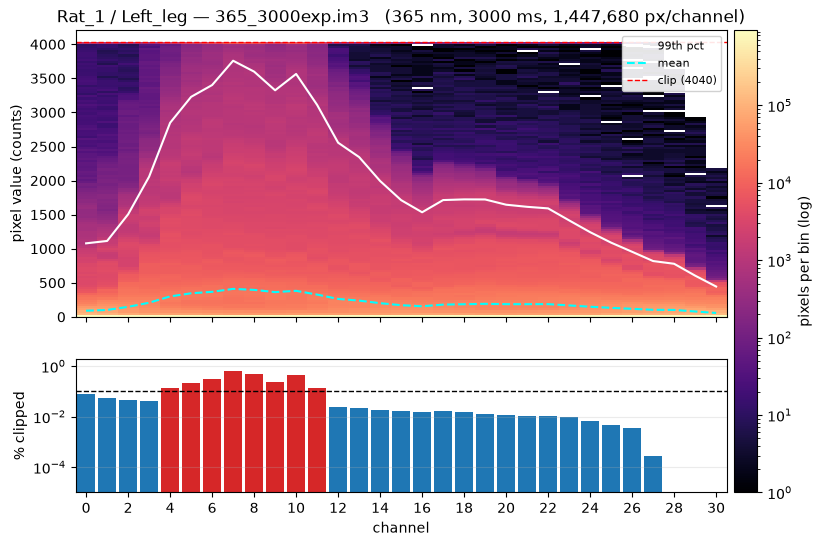

Rat_1/Left_leg/365_3000exp.im3      worst   0.64%   over 0.1%: 4-11


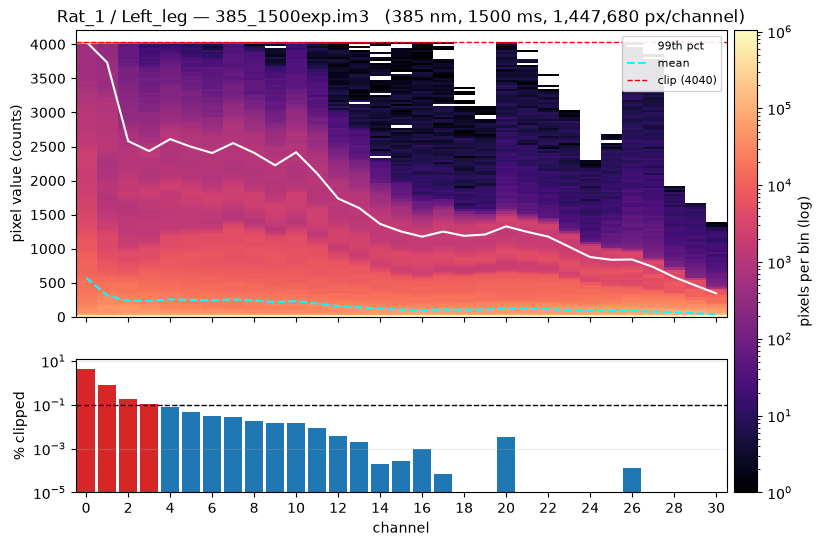

Rat_1/Left_leg/385_1500exp.im3      worst   4.18%   over 0.1%: 0-3


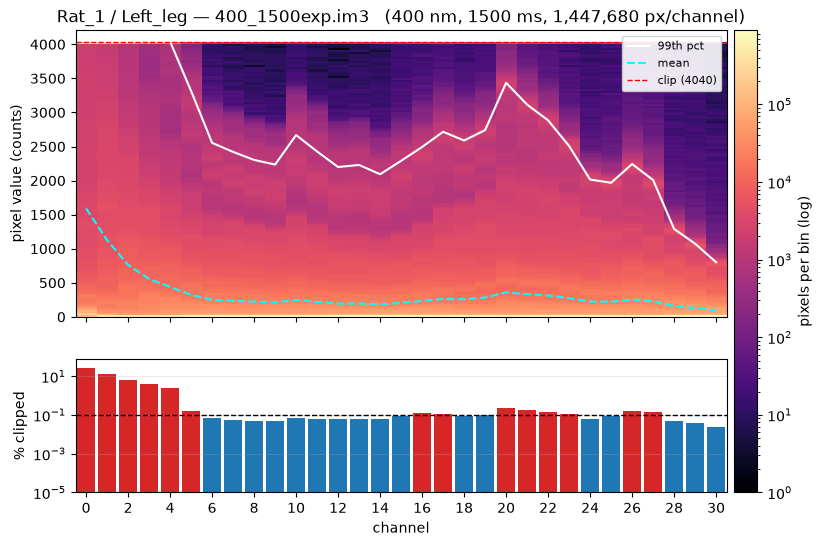

Rat_1/Left_leg/400_1500exp.im3      worst  26.38%   over 0.1%: 0-5, 16-17, 20-23, 26-27


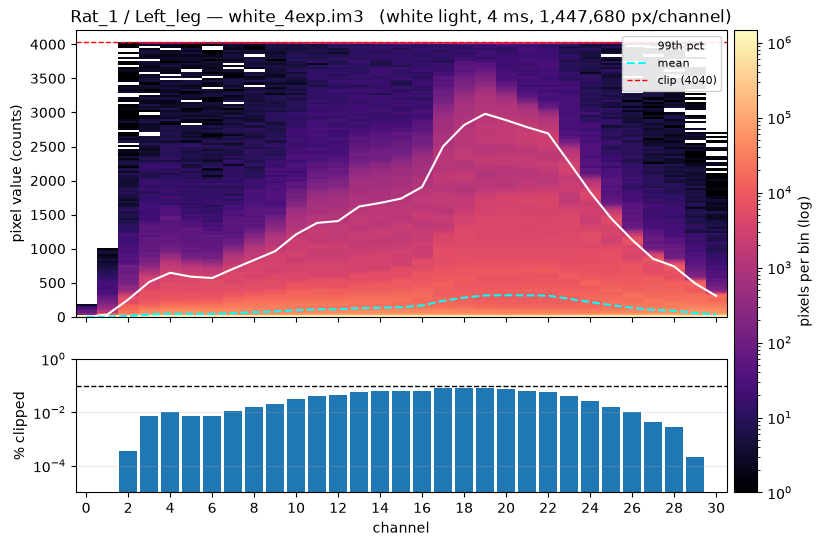

Rat_1/Left_leg/white_4exp.im3       worst   0.08%   over 0.1%: none


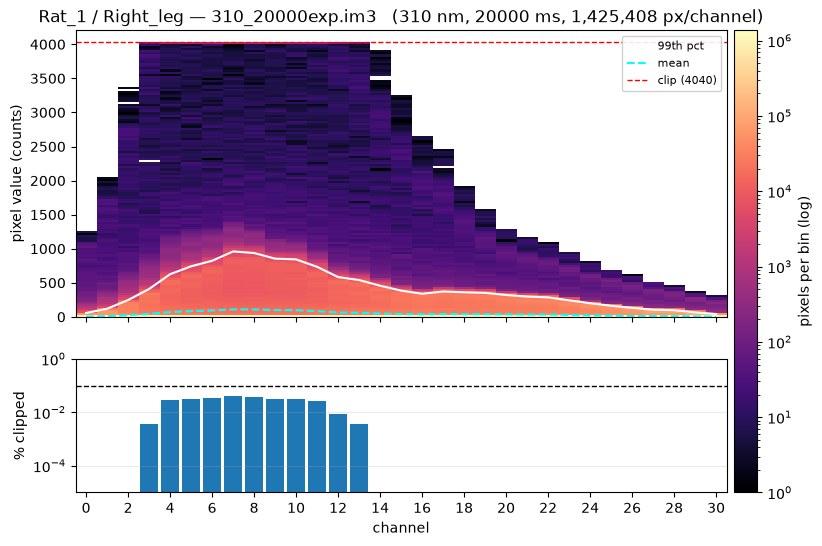

Rat_1/Right_leg/310_20000exp.im3     worst   0.04%   over 0.1%: none


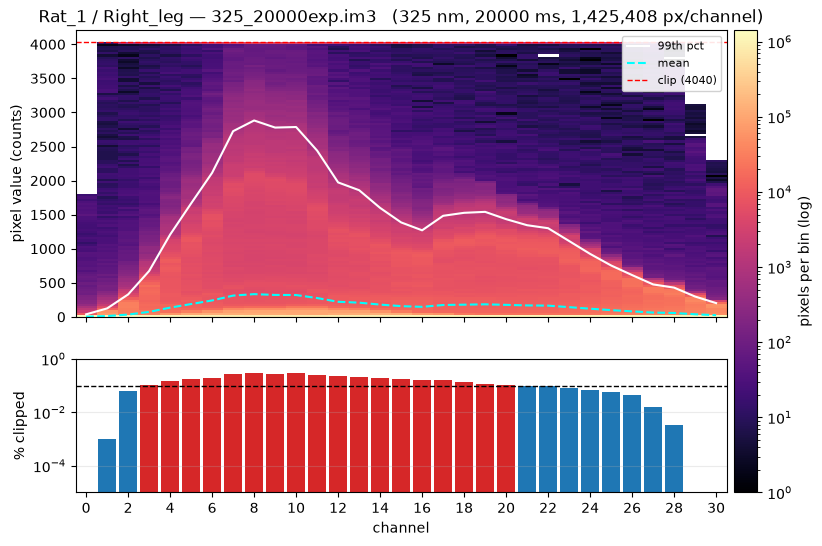

Rat_1/Right_leg/325_20000exp.im3     worst   0.29%   over 0.1%: 3-20


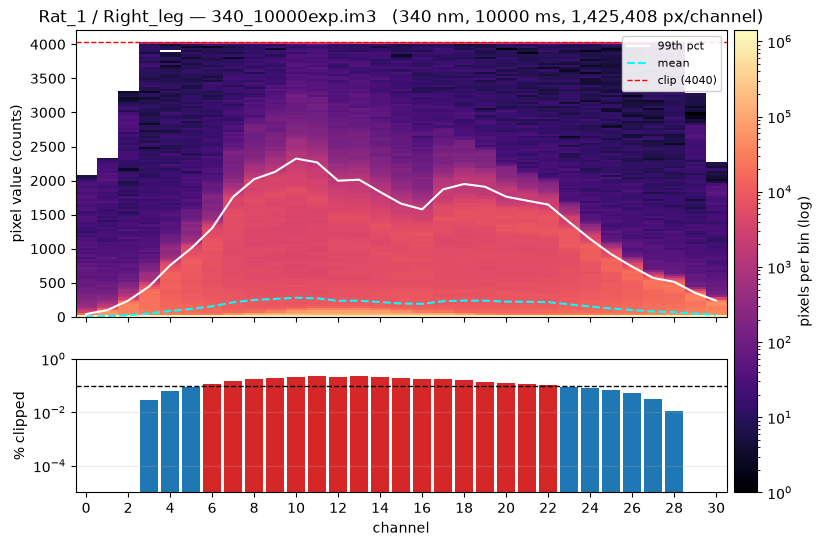

Rat_1/Right_leg/340_10000exp.im3     worst   0.22%   over 0.1%: 6-22


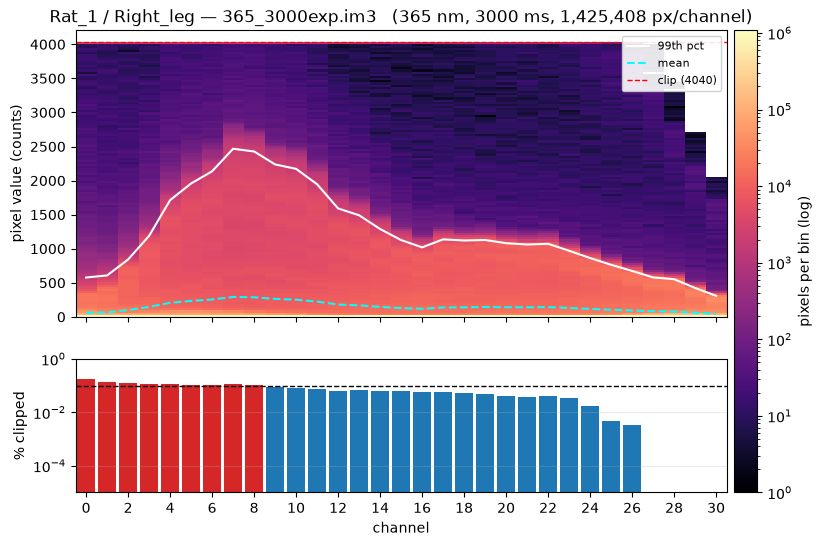

Rat_1/Right_leg/365_3000exp.im3      worst   0.18%   over 0.1%: 0-8


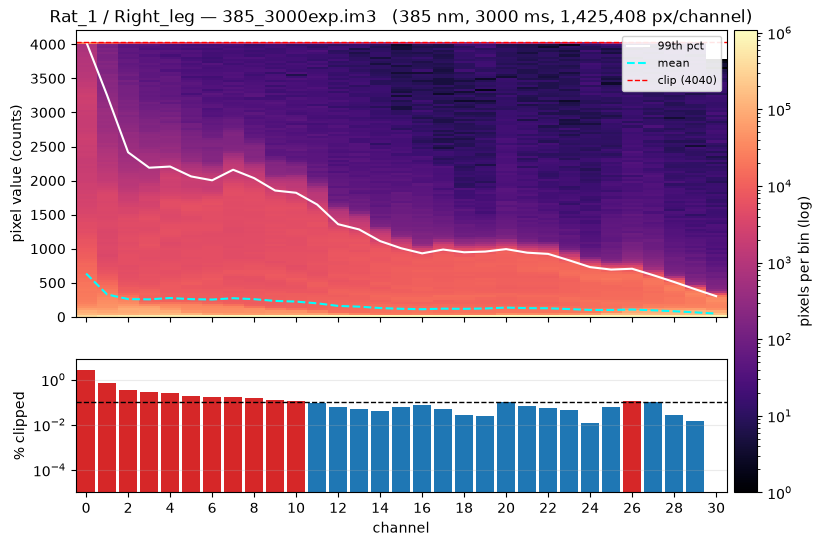

Rat_1/Right_leg/385_3000exp.im3      worst   2.74%   over 0.1%: 0-10, 26


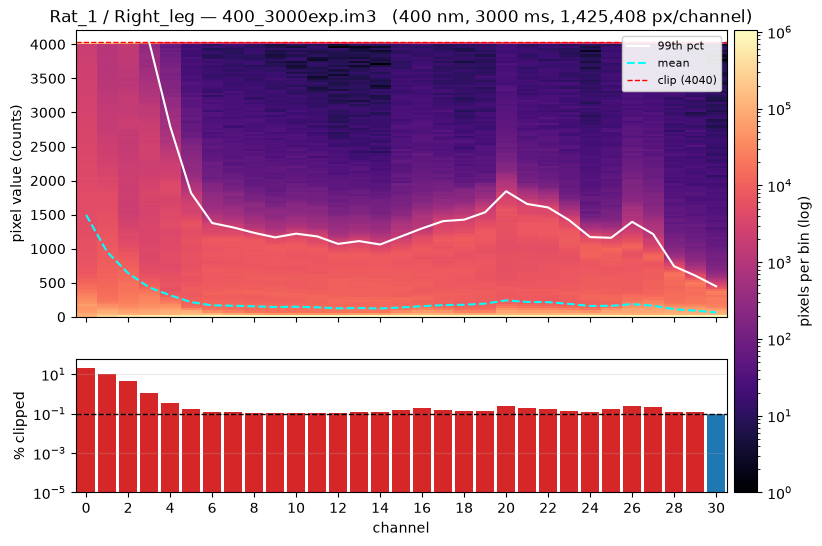

Rat_1/Right_leg/400_3000exp.im3      worst  20.06%   over 0.1%: 0-29


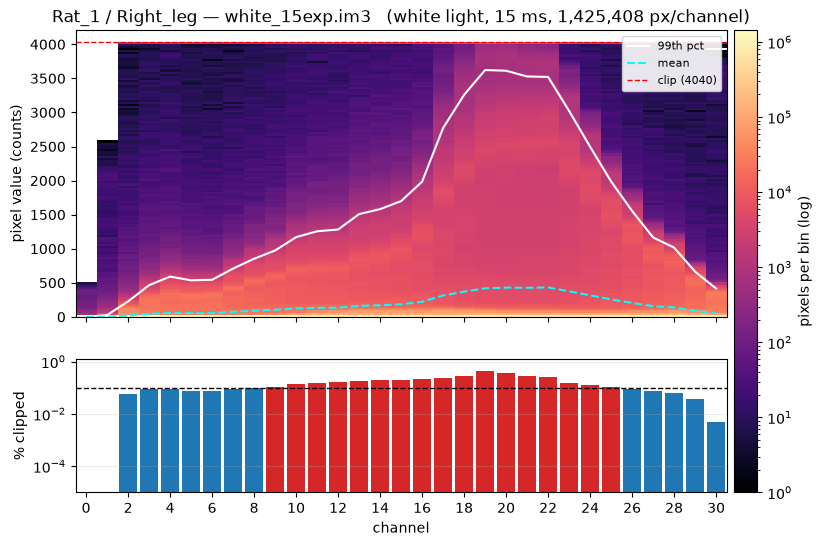

Rat_1/Right_leg/white_15exp.im3      worst   0.42%   over 0.1%: 9-25


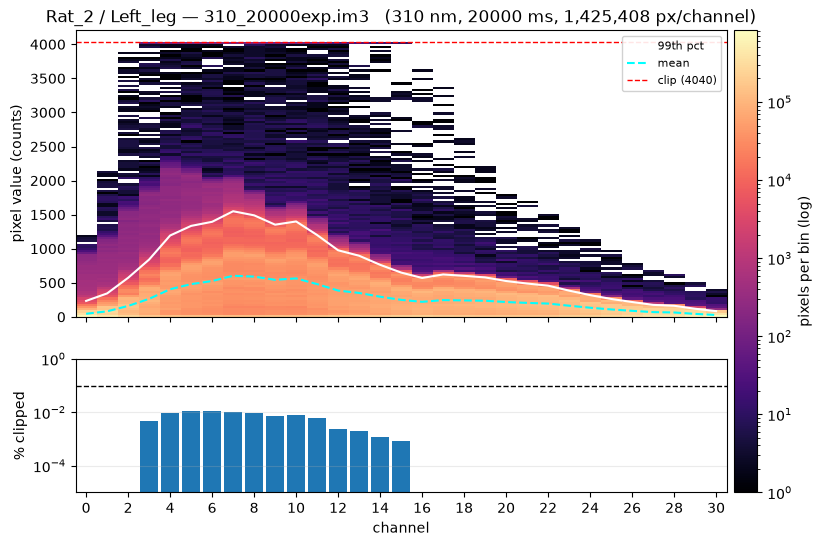

Rat_2/Left_leg/310_20000exp.im3     worst   0.01%   over 0.1%: none


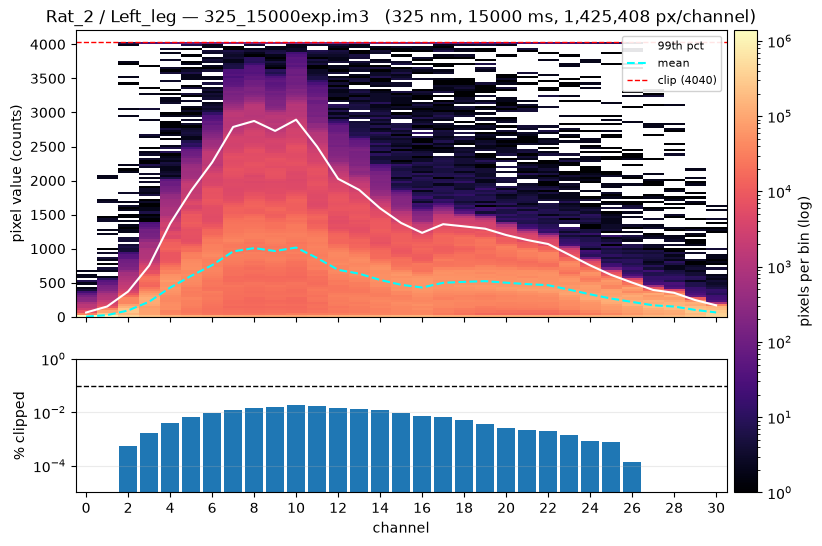

Rat_2/Left_leg/325_15000exp.im3     worst   0.02%   over 0.1%: none


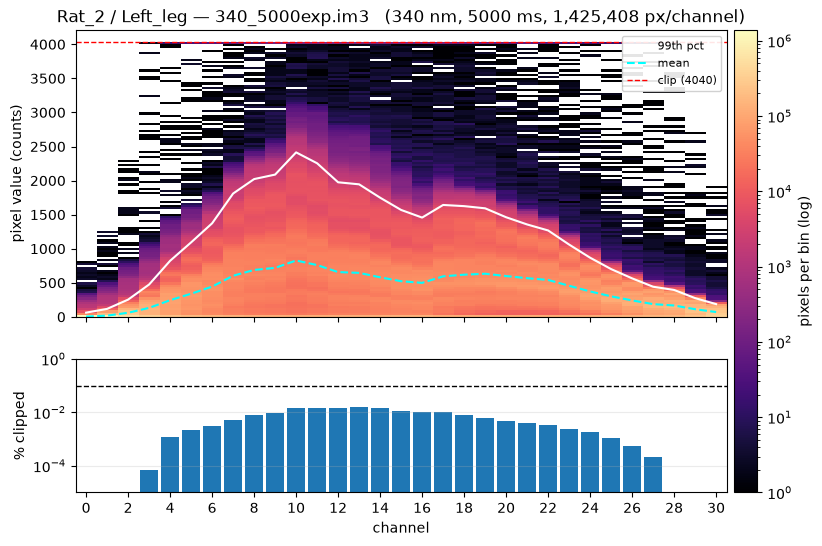

Rat_2/Left_leg/340_5000exp.im3      worst   0.02%   over 0.1%: none


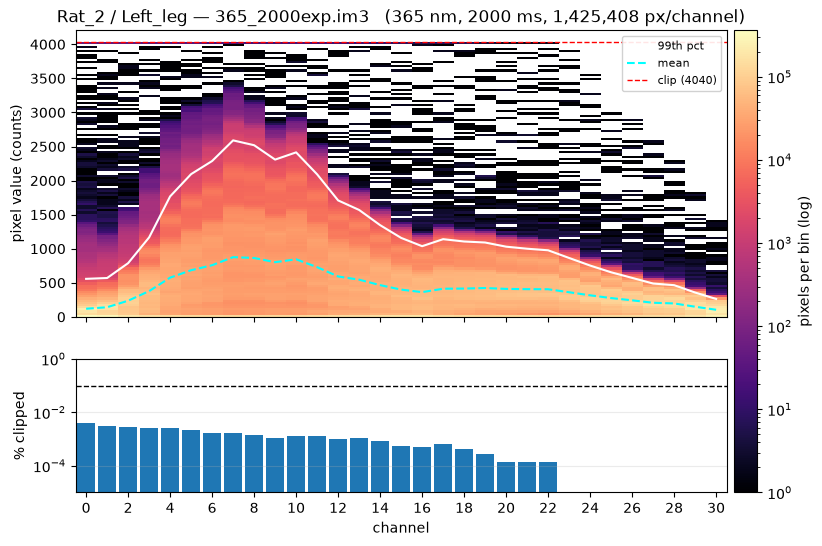

Rat_2/Left_leg/365_2000exp.im3      worst   0.00%   over 0.1%: none


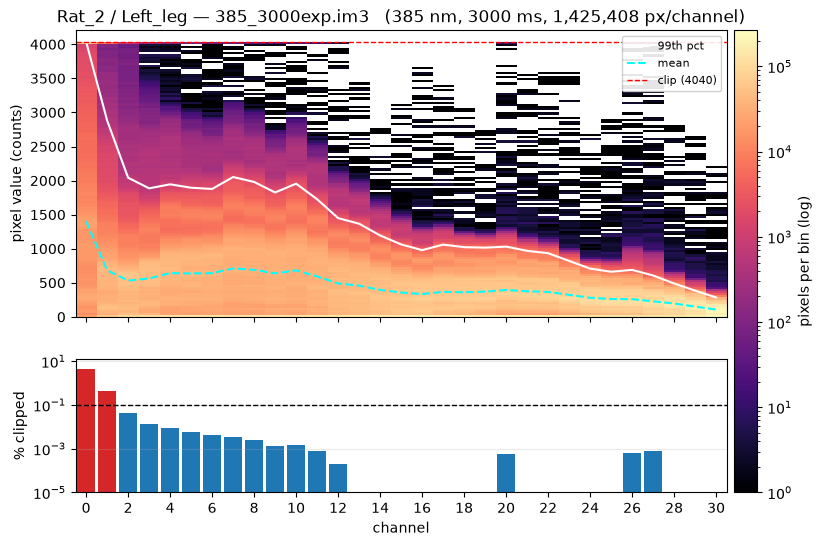

Rat_2/Left_leg/385_3000exp.im3      worst   4.29%   over 0.1%: 0-1


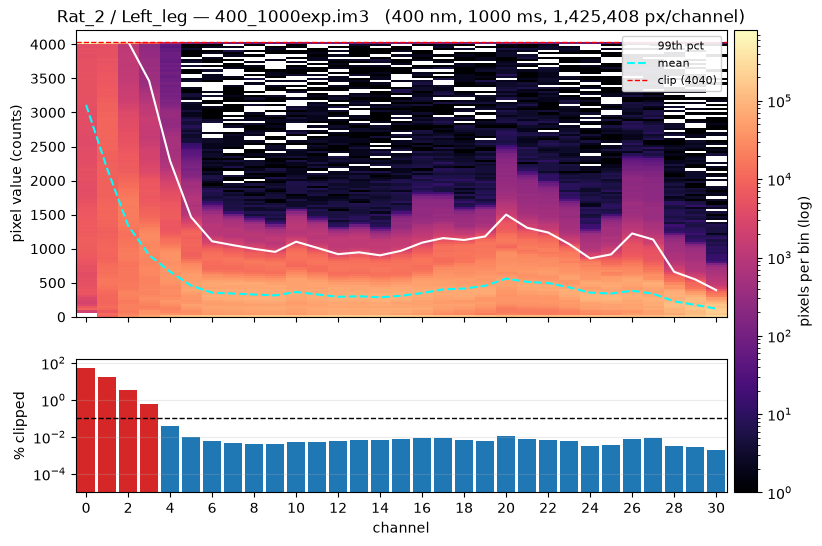

Rat_2/Left_leg/400_1000exp.im3      worst  55.26%   over 0.1%: 0-3


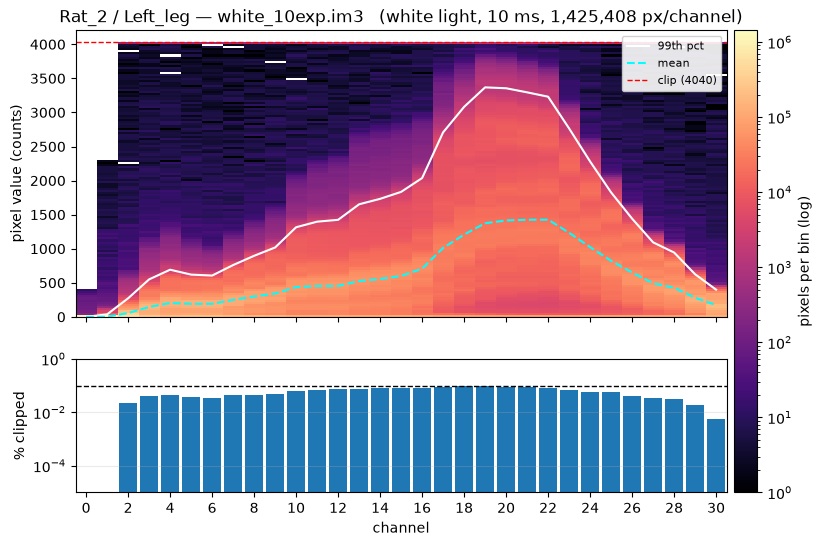

Rat_2/Left_leg/white_10exp.im3      worst   0.10%   over 0.1%: none


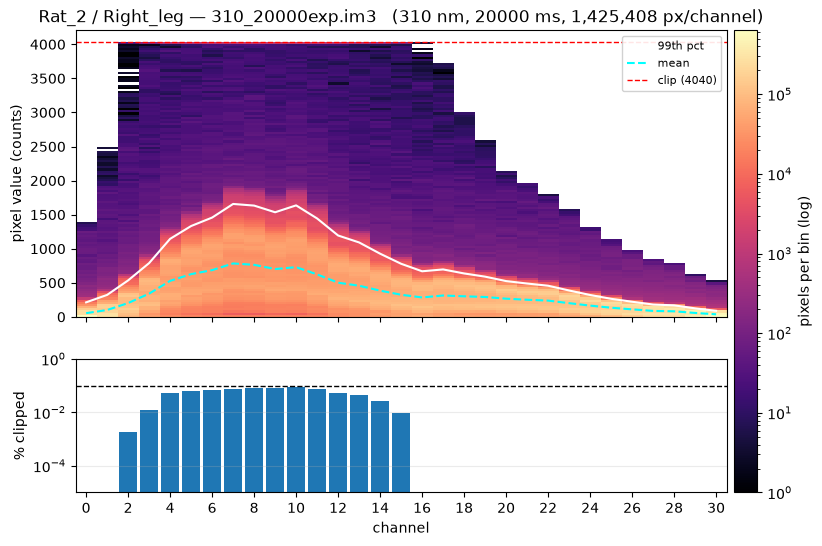

Rat_2/Right_leg/310_20000exp.im3     worst   0.09%   over 0.1%: none


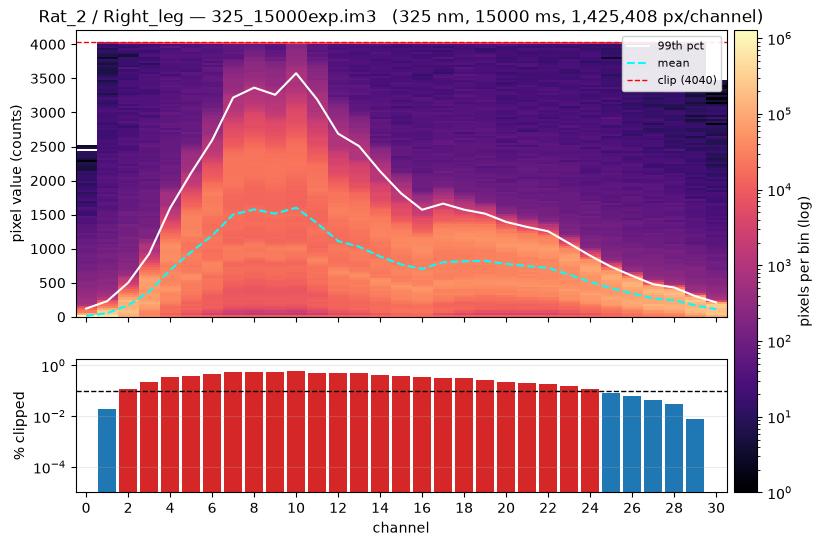

Rat_2/Right_leg/325_15000exp.im3     worst   0.61%   over 0.1%: 2-24


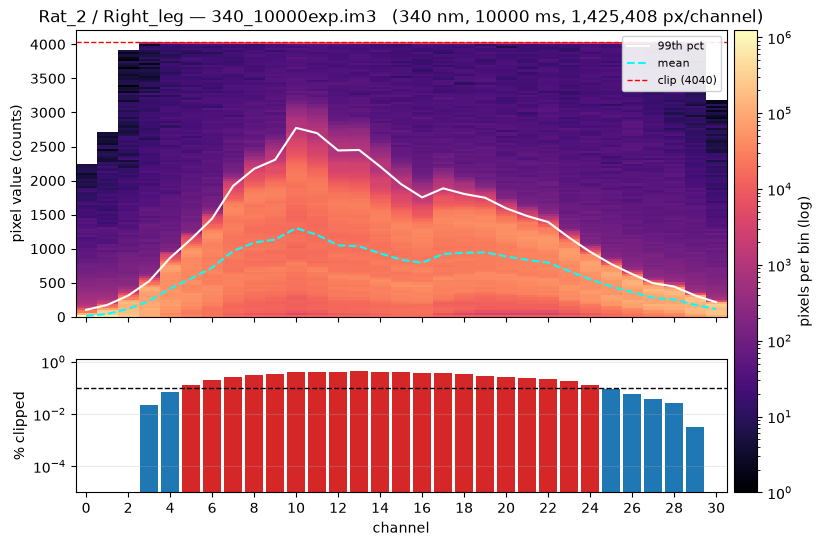

Rat_2/Right_leg/340_10000exp.im3     worst   0.43%   over 0.1%: 5-24


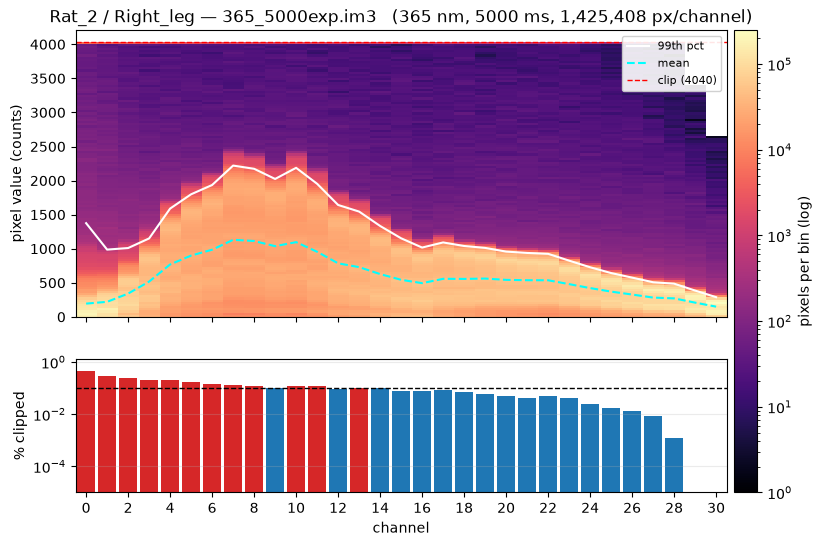

Rat_2/Right_leg/365_5000exp.im3      worst   0.44%   over 0.1%: 0-8, 10-11, 13


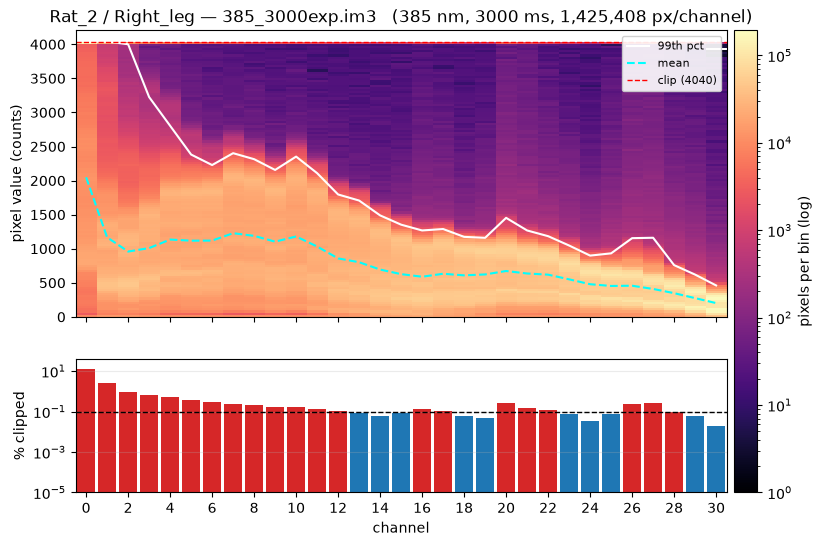

Rat_2/Right_leg/385_3000exp.im3      worst  13.35%   over 0.1%: 0-12, 16-17, 20-22, 26-28


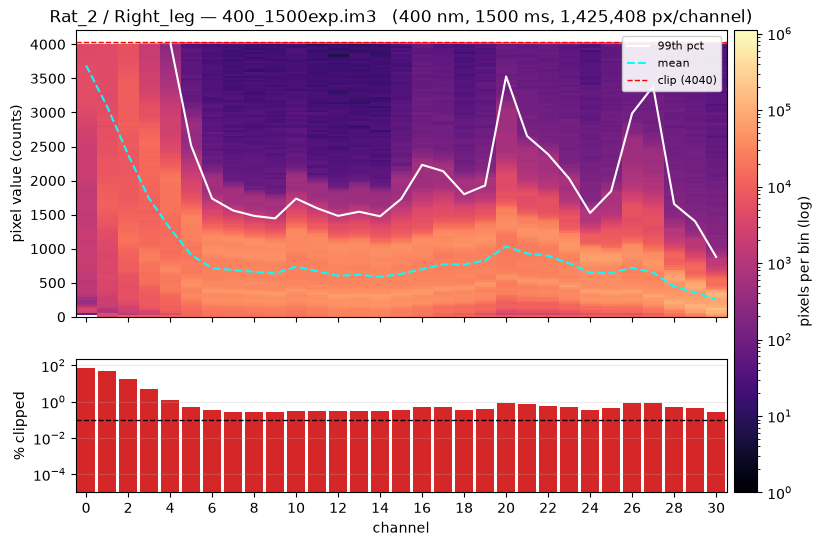

Rat_2/Right_leg/400_1500exp.im3      worst  76.63%   over 0.1%: 0-30


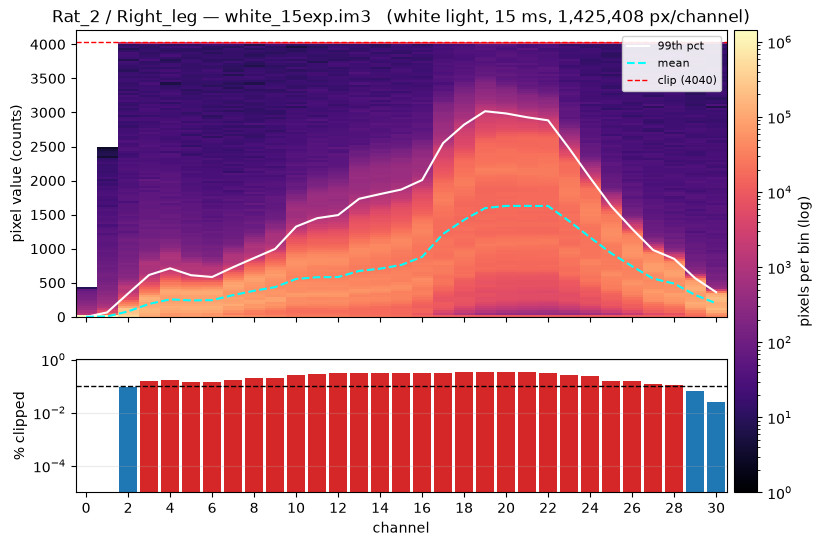

Rat_2/Right_leg/white_15exp.im3      worst   0.35%   over 0.1%: 3-28


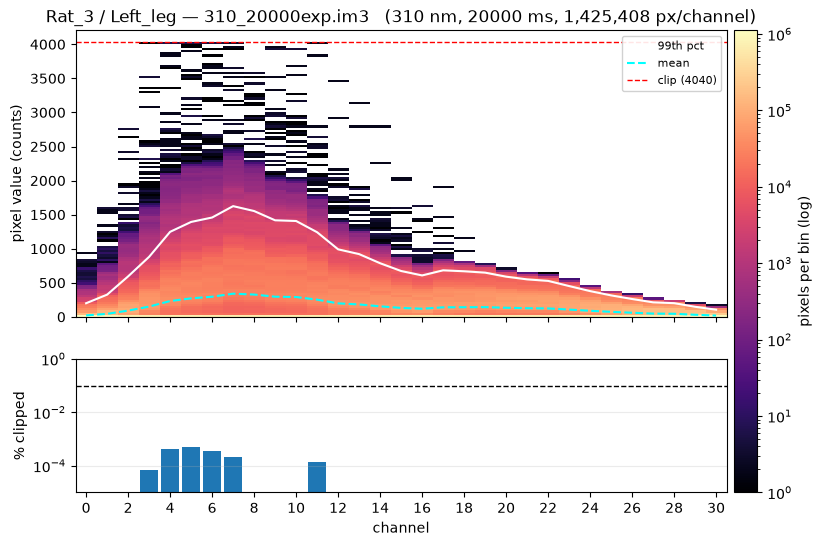

Rat_3/Left_leg/310_20000exp.im3     worst   0.00%   over 0.1%: none


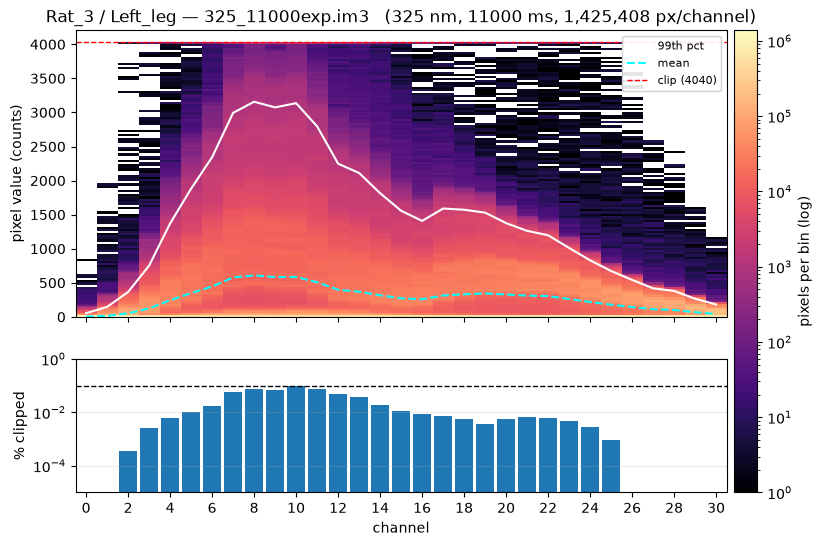

Rat_3/Left_leg/325_11000exp.im3     worst   0.09%   over 0.1%: none


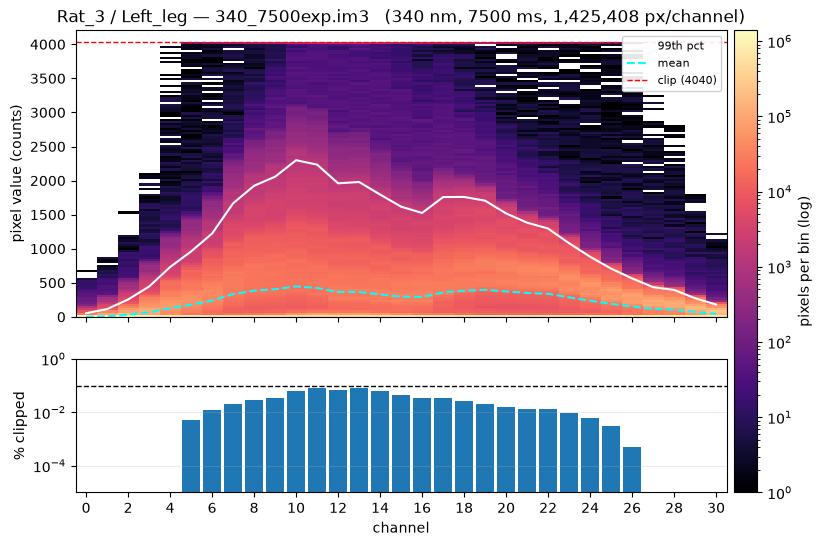

Rat_3/Left_leg/340_7500exp.im3      worst   0.08%   over 0.1%: none


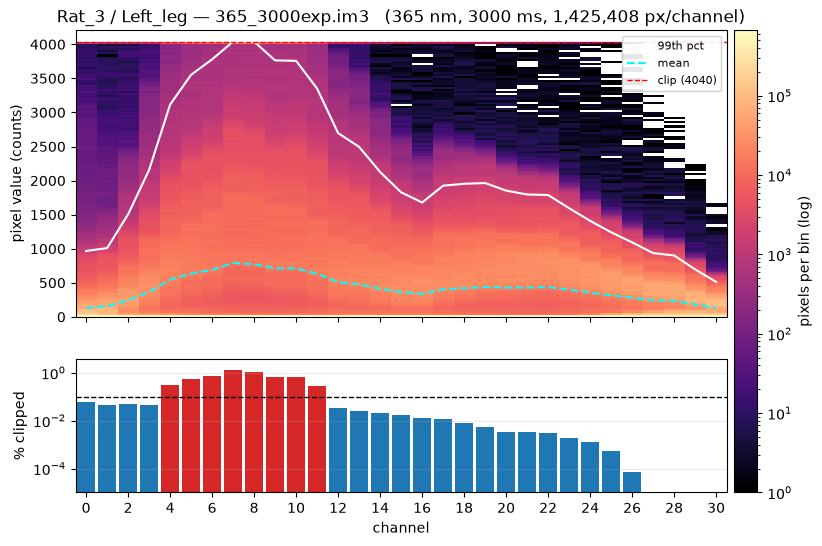

Rat_3/Left_leg/365_3000exp.im3      worst   1.26%   over 0.1%: 4-11


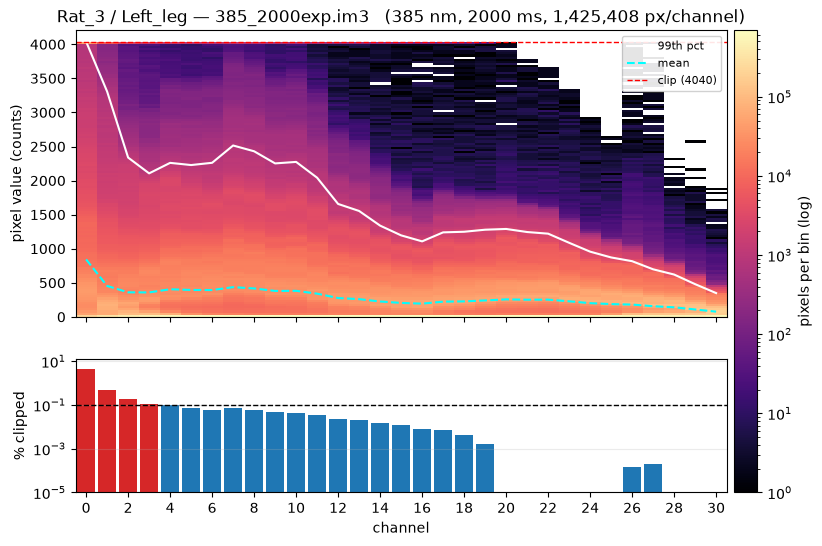

Rat_3/Left_leg/385_2000exp.im3      worst   4.28%   over 0.1%: 0-3


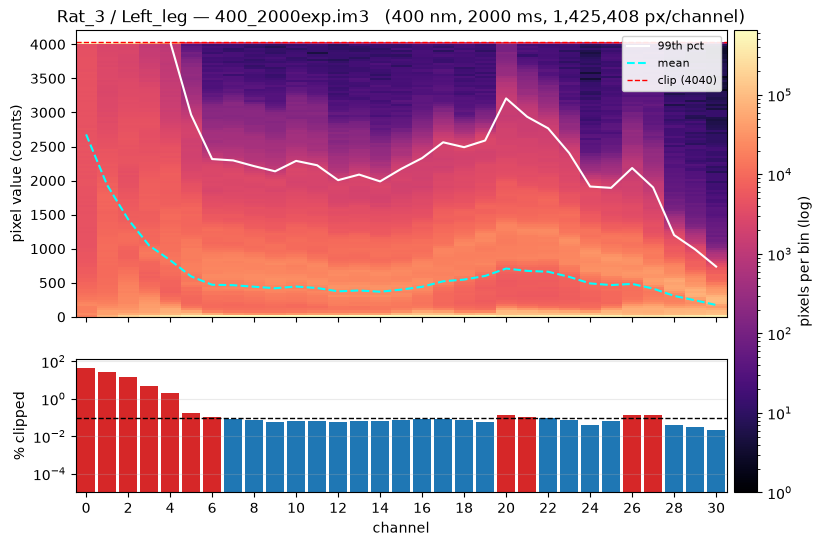

Rat_3/Left_leg/400_2000exp.im3      worst  45.07%   over 0.1%: 0-6, 20-21, 26-27


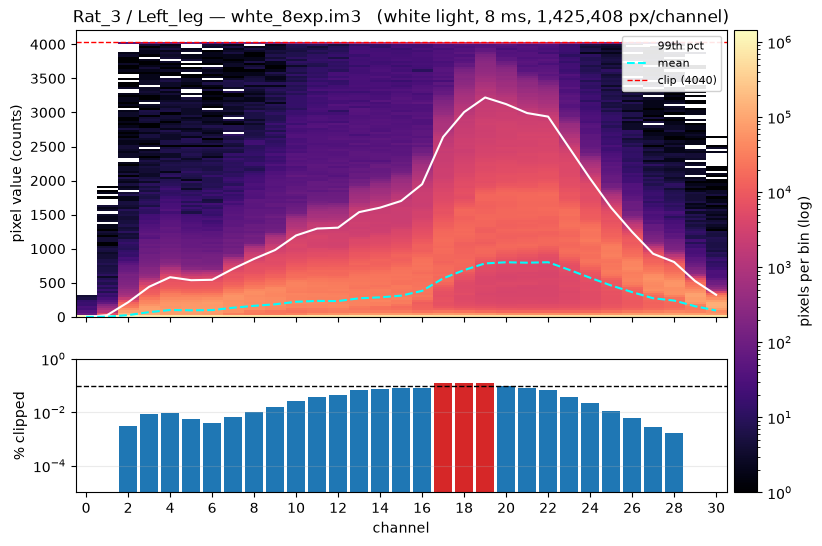

Rat_3/Left_leg/whte_8exp.im3        worst   0.12%   over 0.1%: 17-19


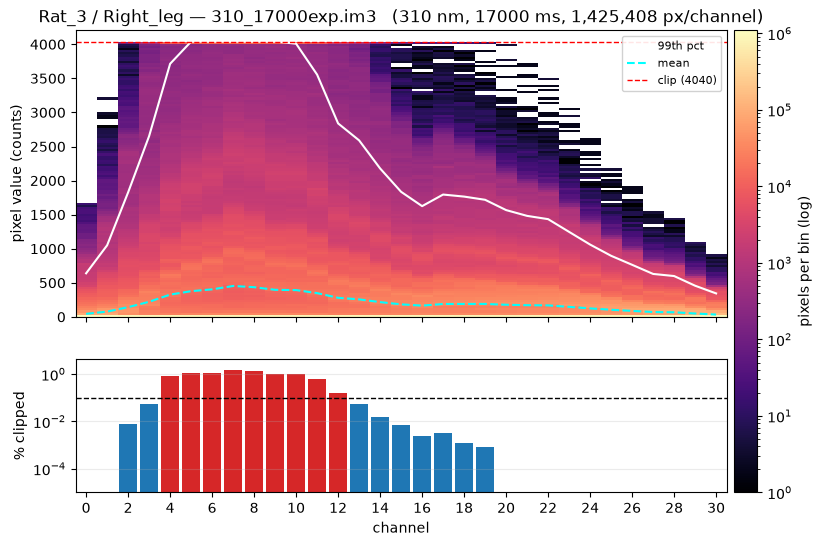

Rat_3/Right_leg/310_17000exp.im3     worst   1.46%   over 0.1%: 4-12


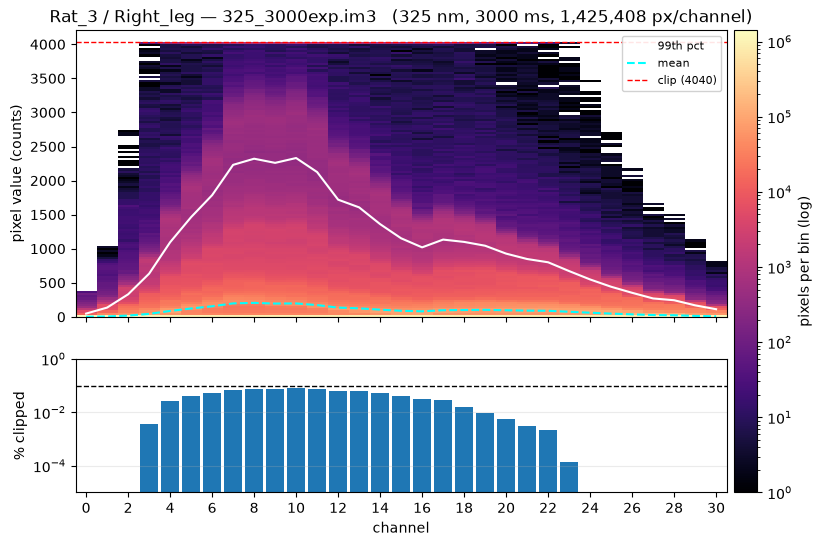

Rat_3/Right_leg/325_3000exp.im3      worst   0.08%   over 0.1%: none


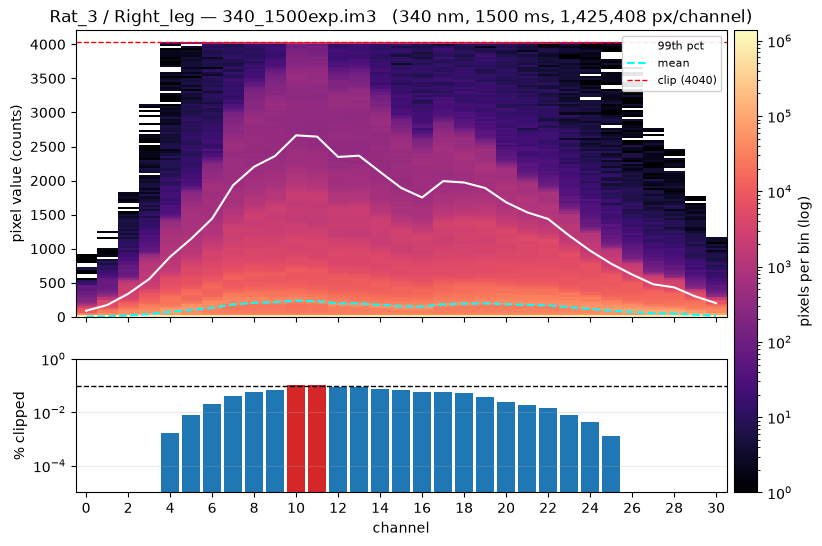

Rat_3/Right_leg/340_1500exp.im3      worst   0.11%   over 0.1%: 10-11


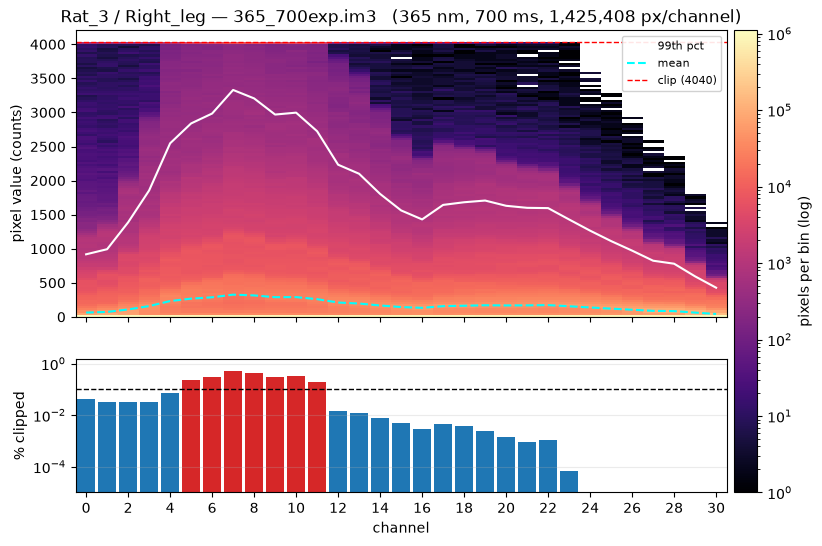

Rat_3/Right_leg/365_700exp.im3       worst   0.51%   over 0.1%: 5-11


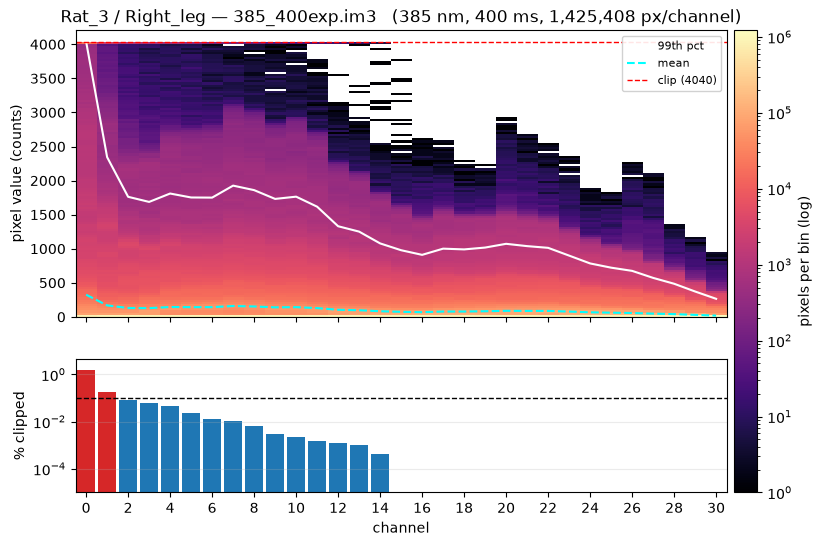

Rat_3/Right_leg/385_400exp.im3       worst   1.52%   over 0.1%: 0-1


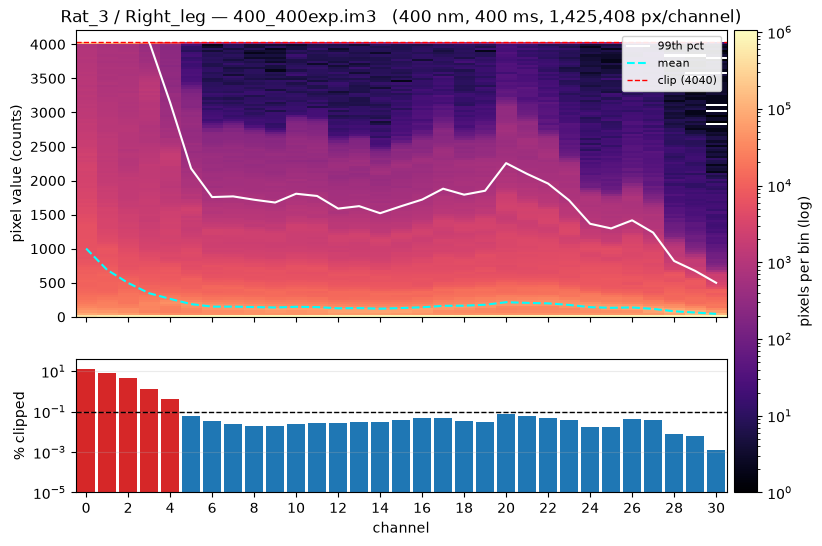

Rat_3/Right_leg/400_400exp.im3       worst  13.55%   over 0.1%: 0-4


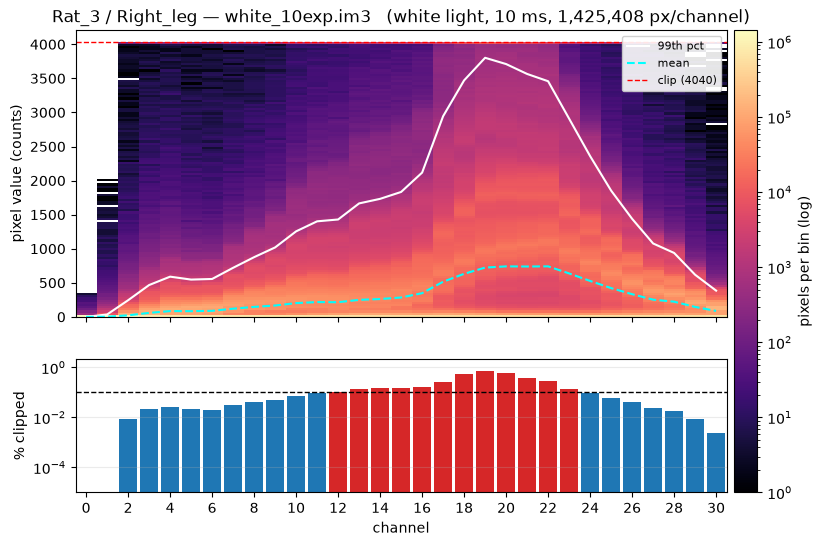

Rat_3/Right_leg/white_10exp.im3      worst   0.73%   over 0.1%: 12-23

channels over 0.1% clipped, per cube
   Rat_1/Left_leg   310_20000exp.im3      5  4-8
   Rat_1/Left_leg   325_5000exp.im3       2  10-11
   Rat_1/Left_leg   340_5000exp.im3       0  none
   Rat_1/Left_leg   365_3000exp.im3       8  4-11
   Rat_1/Left_leg   385_1500exp.im3       4  0-3
   Rat_1/Left_leg   400_1500exp.im3      14  0-5, 16-17, 20-23, 26-27
   Rat_1/Left_leg   white_4exp.im3        0  none
   Rat_1/Right_leg  310_20000exp.im3      0  none
   Rat_1/Right_leg  325_20000exp.im3     18  3-20
   Rat_1/Right_leg  340_10000exp.im3     17  6-22
   Rat_1/Right_leg  365_3000exp.im3       9  0-8
   Rat_1/Right_leg  385_3000exp.im3      12  0-10, 26
   Rat_1/Right_leg  400_3000exp.im3      30  0-29
   Rat_1/Right_leg  white_15exp.im3      17  9-25
   Rat_2/Left_leg   310_20000exp.im3      0  none
   Rat_2/Left_leg   325_15000exp.im3      0  none
   Rat_2/Left_leg   340_5000exp.im3       0  none
   Rat_2/Left_leg   

In [2]:
# --- Step 5: one distribution plot per cube, for every cube of 12.09 ---------
# The same picture as Step 4, drawn 42 times: 3 rats x 2 legs x 7 excitations.
# Each figure is one .im3 — its 31 emission bands across the x axis, the spread
# of pixel values up the y axis, and underneath, the share of pixels sitting
# exactly on the 4040-count clip. That bottom strip is the one to read when
# deciding what to throw away: a bar above the flag line means the channel's
# bright pixels are censored, so its values are a lower bound, not a
# measurement. The flagged channels of each cube are also printed as ranges.
#
# Reading is direct from the .im3 (no JVM): the exact per-value histogram of
# each channel gives percentiles and clip counts without sorting 1.4 M pixels.
# 42 cubes, ~3.8 GB, roughly a minute.
import mmap
import re
import struct
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

DAY = Path("/Users/zmkoyan/User Files/multi-excitation-hsi-in-vivo-rats/Data/Raw/Rat_Cubes/12.09")
SAT = 4040          # sensor clipping level, in counts
FLAG = 0.1          # % of clipped pixels at which a channel is called suspect
NBINS = 128         # value bins in the distribution panel
ROWS = 128          # rows of a cube scanned at a time


def _im3_data(path):
    """(offset, X, Y, C) of an .im3's pixel block, without reading the pixels."""
    def record(buf, p):
        n, = struct.unpack_from("<i", buf, p)
        name = bytes(buf[p + 4:p + 4 + n]).decode("utf-8", "replace")
        p += 4 + n
        length, rtype = struct.unpack_from("<ii", buf, p)
        return (name, rtype, p + 8, length - 8), p + 8 + length - 8

    def kids(buf, rec):
        p, end, out = rec[2] + 8, rec[2] + rec[3], []
        while p < end - 8:
            child, p = record(buf, p)
            out.append(child)
        return out

    def find(buf, rec, name):
        return next(c for c in kids(buf, rec) if c[0] == name)

    with open(path, "rb") as fh, mmap.mmap(fh.fileno(), 0, access=mmap.ACCESS_READ) as mm:
        p, top = 4, []
        while p < len(mm) - 16:
            rec, p = record(mm, p)
            top.append(rec)
        inner = kids(mm, find(mm, top[-1], "DataSet"))[0]
        data = find(mm, inner, "Data")
        _, X, Y, C = struct.unpack_from("<iiii", mm, data[2])
    return data[2] + 16, X, Y, C


def channel_histograms(path):
    """Exact (C, value) count matrix of a cube, read in row chunks."""
    offset, X, Y, C = _im3_data(path)
    cube = np.memmap(path, dtype="<u2", mode="r", offset=offset, shape=(Y, X, C))
    top = 0
    for y in range(0, Y, ROWS):
        top = max(top, int(cube[y:y + ROWS].max()))
    hist = np.zeros((C, top + 1), dtype=np.int64)
    for y in range(0, Y, ROWS):
        chunk = np.asarray(cube[y:y + ROWS])
        for c in range(C):
            hist[c] += np.bincount(chunk[:, :, c].ravel(), minlength=top + 1)
    del cube
    return hist, X * Y


def channel_stats(hist, npix):
    """mean / p1 / p99 / max / % clipped per channel, straight from the counts."""
    values = np.arange(hist.shape[1], dtype=np.float64)
    cum = np.cumsum(hist, axis=1)
    p1 = np.array([np.searchsorted(row, 0.01 * npix) for row in cum])
    p99 = np.array([np.searchsorted(row, 0.99 * npix) for row in cum])
    mean = (hist * values).sum(axis=1) / npix
    top = np.array([np.nonzero(row)[0][-1] for row in hist])
    clipped = 100.0 * hist[:, SAT:].sum(axis=1) / npix if hist.shape[1] > SAT \
        else np.zeros(hist.shape[0])
    return {"mean": mean, "p1": p1, "p99": p99, "max": top, "clipped": clipped}


def ranges(channels):
    """[0,1,2,5] -> '0-2, 5' so a long list of channels reads at a glance."""
    out, start, prev = [], None, None
    for c in list(channels) + [None]:
        if start is None:
            start, prev = c, c
        elif c is not None and c == prev + 1:
            prev = c
        else:
            out.append(f"{start}" if start == prev else f"{start}-{prev}")
            start, prev = c, c
    return ", ".join(out) if out else "none"


def band_order_key(path):
    """Excitation ascending, white light last (one leg spells it 'whte')."""
    m = re.match(r"\s*(\d{3})", path.stem)
    return (0, int(m.group(1)), path.stem.lower()) if m else (1, 0, path.stem.lower())


def plot_cube(path, hist, stats, npix):
    """One cube: value distribution per channel, and its clipped fraction."""
    C = hist.shape[0]
    edges = np.linspace(0, hist.shape[1], NBINS + 1)
    binned = np.add.reduceat(hist, np.floor(edges[:-1]).astype(int), axis=1).T

    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 6), height_ratios=[3, 1.4],
                                  sharex=True)
    im = ax.imshow(np.ma.masked_equal(binned, 0), origin="lower", aspect="auto",
                   extent=[-0.5, C - 0.5, edges[0], edges[-1]],
                   norm=LogNorm(vmin=1, vmax=binned.max()), cmap="magma",
                   interpolation="nearest")
    ax.plot(range(C), stats["p99"], color="white", lw=1.5, label="99th pct")
    ax.plot(range(C), stats["mean"], color="cyan", lw=1.5, ls="--", label="mean")
    ax.axhline(SAT, color="red", ls="--", lw=1, label=f"clip ({SAT})")
    ax.set_ylim(0, edges[-1] * 1.04)
    ax.set_ylabel("pixel value (counts)")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    fig.colorbar(im, ax=[ax, ax2], label="pixels per bin (log)", pad=0.01)

    # A channel with no clipped pixel at all simply has no bar; the scale goes
    # low enough that a single clipped pixel in 1.4 M still draws one.
    bad = stats["clipped"] > FLAG
    ax2.bar(np.arange(C)[~bad], stats["clipped"][~bad], color="tab:blue", width=0.85)
    ax2.bar(np.arange(C)[bad], stats["clipped"][bad], color="tab:red", width=0.85)
    ax2.axhline(FLAG, color="k", ls="--", lw=1)
    ax2.set_yscale("log")
    ax2.set_ylim(1e-5, max(stats["clipped"].max() * 3, 1.0))
    ax2.set_ylabel("% clipped")
    ax2.set_xlabel("channel")
    ax2.set_xticks(range(0, C, 2))
    ax2.grid(axis="y", alpha=0.25)

    m = re.match(r"\s*(\d{3})", path.stem)
    n = re.search(r"(\d+)exp", path.stem)
    ax.set_title(f"{path.parts[-4]} / {path.parts[-3]} — {path.name}   "
                 f"({m.group(1) + ' nm' if m else 'white light'}, "
                 f"{n.group(1) if n else '?'} ms, {npix:,} px/channel)")
    plt.show()


cubes = sorted(DAY.glob("*/*/Distinct_Cubes/*.im3"),
               key=lambda p: (p.parts[-4], p.parts[-3], band_order_key(p)))
print(f"{len(cubes)} cubes under {DAY}\n")

summary = []
for path in cubes:
    hist, npix = channel_histograms(path)
    stats = channel_stats(hist, npix)
    plot_cube(path, hist, stats, npix)
    bad = np.nonzero(stats["clipped"] > FLAG)[0]
    summary.append((path, stats, bad))
    print(f"{path.parts[-4]}/{path.parts[-3]}/{path.name:20s} "
          f"worst {stats['clipped'].max():6.2f}%   over {FLAG}%: {ranges(bad)}", flush=True)

print(f"\nchannels over {FLAG}% clipped, per cube")
for path, stats, bad in summary:
    print(f"  {path.parts[-4]:>6s}/{path.parts[-3]:<10s} {path.name:20s} "
          f"{len(bad):2d}  {ranges(bad)}")